In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [22]:
housing = fetch_california_housing()

X = pd.DataFrame(housing.data, columns=housing.feature_names)
y = pd.Series(housing.target, name="HouseValue")


In [23]:
print("Dataset Shape:")
print(X.shape)

print("\nFeature Names:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

print("\nMissing Values:")
print(X.isnull().sum())

print("\nBasic Statistics:")
print(X.describe())

Dataset Shape:
(20640, 8)

Feature Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']

Target Variable:
HouseValue

Missing Values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
dtype: int64

Basic Statistics:
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
25%        2.563400     18.000000      4.440716      1.006079    787.000000   
50%        3.534800     29.000000      5.229129      1.048780   1166.000000   
75%        4.743250     37.000000      6.052381      1.099526   1725.000000   
max       15.000100  

In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)



In [25]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [26]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}
results = []

best_pipeline = None
best_r2 = -999

In [27]:
for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessing", preprocessor),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    train_r2 = pipeline.score(X_train, y_train)

    results.append([
        name,
        mae,
        mse,
        rmse,
        r2,
        train_r2
    ])

    if r2 > best_r2:
        best_r2 = r2
        best_pipeline = pipeline
        best_predictions = y_pred
        best_model_name = name
        best_train_r2 = train_r2


In [28]:
results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "MAE",
        "MSE",
        "RMSE",
        "R²",
        "Train R²"
    ]
)

print("\nModel Performance")
print(results_df)


Model Performance
               Model       MAE       MSE      RMSE        R²  Train R²
0  Linear Regression  0.533200  0.555892  0.745581  0.575788  0.612551
1   Ridge Regression  0.533193  0.555855  0.745557  0.575816  0.612551
2      Random Forest  0.327425  0.255170  0.505143  0.805275  0.973565


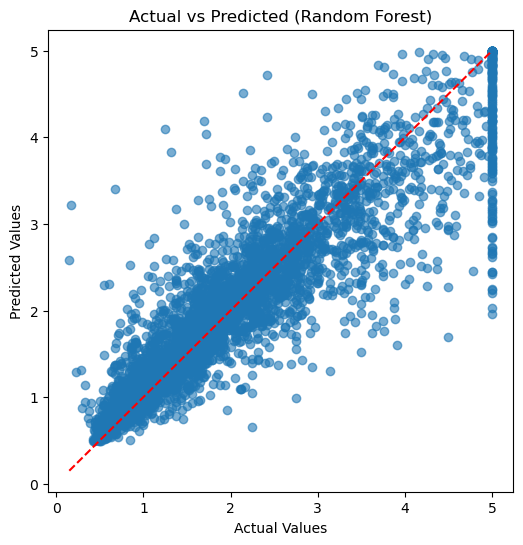

In [29]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, best_predictions, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title(f"Actual vs Predicted ({best_model_name})")
plt.show()

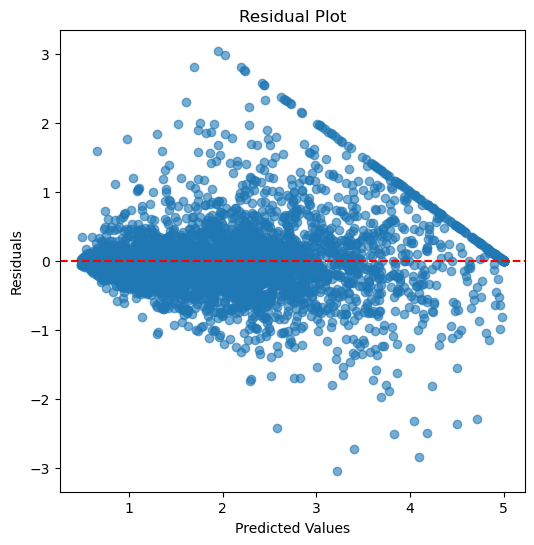

In [30]:
residuals = y_test - best_predictions

plt.figure(figsize=(6,6))
plt.scatter(best_predictions, residuals, alpha=0.6)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()


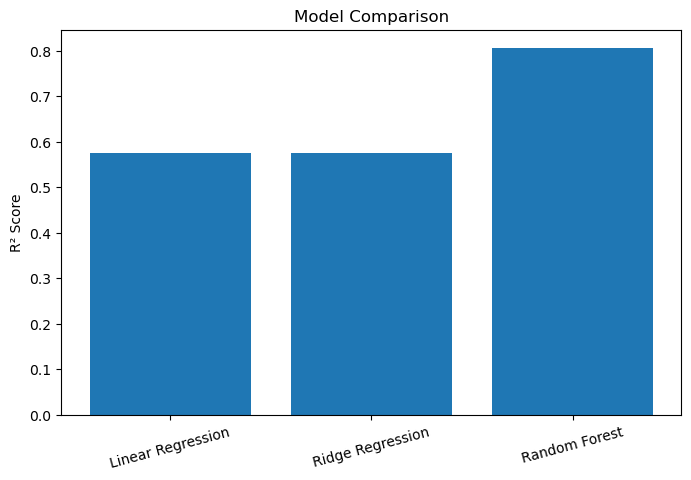

In [31]:
plt.figure(figsize=(8,5))
plt.bar(results_df["Model"], results_df["R²"])
plt.ylabel("R² Score")
plt.title("Model Comparison")
plt.xticks(rotation=15)
plt.show()


In [32]:
print("\nBest Model:", best_model_name)
print("Training R²:", round(best_train_r2, 4))
print("Testing R² :", round(best_r2, 4))

if best_train_r2 - best_r2 > 0.10:
    print("Interpretation: The model shows signs of overfitting.")
elif best_r2 < 0.50:
    print("Interpretation: The model may be underfitting.")
else:
    print("Interpretation: The model generalizes well.")



Best Model: Random Forest
Training R²: 0.9736
Testing R² : 0.8053
Interpretation: The model shows signs of overfitting.


In [ ]:
The best regression model is selected based on the highest R² score
and lowest error values (MAE, MSE, RMSE).
A higher R² means the model explains more variation in house prices,
while lower errors indicate better prediction accuracy.

NameError: name 'best_row' is not defined

The best regression model is selected based on the highest R² score
and lowest error values (MAE, MSE, RMSE).
A higher R² means the model explains more variation in house prices,
while lower errors indicate better prediction accuracy.